In [20]:
from modules import data_preprocessing as dataPrep
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from termcolor import colored

KITS23_PATH = '/home/marcel/Repos/Data/kits23'
TUMOR_INSTANCE_DATA_PATH = 'data/annotation_empty_75mm.csv'
BBOX_PATH = 'data/data_bounding_box.csv'

In [2]:
df = dataPrep.extract_tumor_kidney_bounding_boxes(TUMOR_INSTANCE_DATA_PATH, KITS23_PATH)

df.to_csv(BBOX_PATH, index=False)

Calculating bounding boxes: 100%|██████████| 434/434 [20:11<00:00,  2.79s/it]


In [8]:
df = pd.read_csv(BBOX_PATH)
df

,tumor_id,size_z,size_y,size_x
0,case_00000_t1,215,89,72
1,case_00001_t1,214,117,92
2,case_00001_t2,214,117,92
3,case_00002_t1,112,89,90
4,case_00003_t1,93,101,88
...,...,...,...,...
429,case_00586_t3,37,83,108
430,case_00586_t1,37,79,97
431,case_00586_t2,36,78,97
432,case_00587_t1,23,80,86


In [12]:
df.describe()

,size_z,size_y,size_x
count,434.000000,434.000000,434.000000
mean,59.023041,102.638249,96.735023
std,63.067283,19.526154,18.614388
min,13.000000,57.000000,54.000000
25%,21.000000,89.000000,85.250000
50%,33.000000,102.000000,95.000000
75%,55.500000,114.000000,104.750000
max,291.000000,223.000000,271.000000


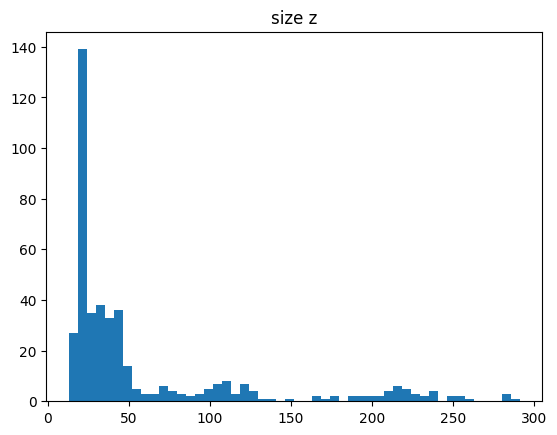

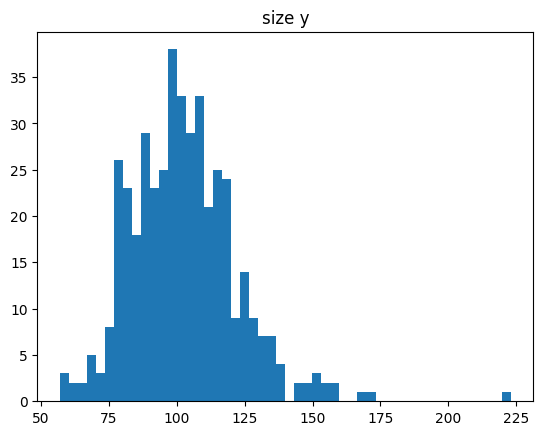

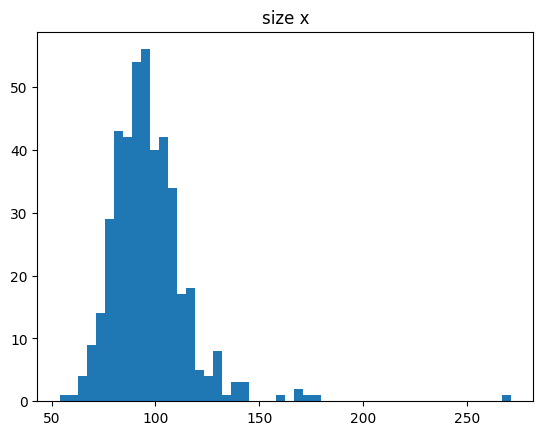

In [17]:
size_z = df['size_z']

plt.hist(size_z, bins=50)
plt.title("size z")
plt.show()

size_y = df['size_y']

plt.hist(size_y, bins=50)
plt.title("size y")
plt.show()

size_x = df['size_x']

plt.hist(size_x, bins=50)
plt.title("size x")
plt.show()

In [21]:
# to determine the ideal ammount of information contained in an image
# we calculate the mean and the average and sum them up (somewhat arbitrary)
limit_z = np.ceil(df['size_z'].mean() + df['size_z'].std()).astype('int')
limit_y = np.ceil(df['size_y'].mean() + df['size_y'].std()).astype('int')
limit_x = np.ceil(df['size_x'].mean() + df['size_x'].std()).astype('int')

print(colored("--- Mean + std ---", "blue"))
print(f"limit z = {limit_z}")
print(f"limit y = {limit_y}")
print(f"limit x = {limit_x}")

--- Mean + std ---
limit z = 123
limit y = 123
limit x = 116


In [22]:
limit_z = np.ceil(df['size_z'].mean()).astype('int')
limit_y = np.ceil(df['size_y'].mean()).astype('int')
limit_x = np.ceil(df['size_x'].mean()).astype('int')

print(colored("--- Mean ---", "blue"))
print(f"limit z = {limit_z}")
print(f"limit y = {limit_y}")
print(f"limit x = {limit_x}")

--- Mean ---
limit z = 60
limit y = 103
limit x = 97
